# LAB1 - Bài 3 (Titanic): Tuổi, giới tính và khả năng sống sót

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")

Đinh Công Vinh Quang - 6451071061


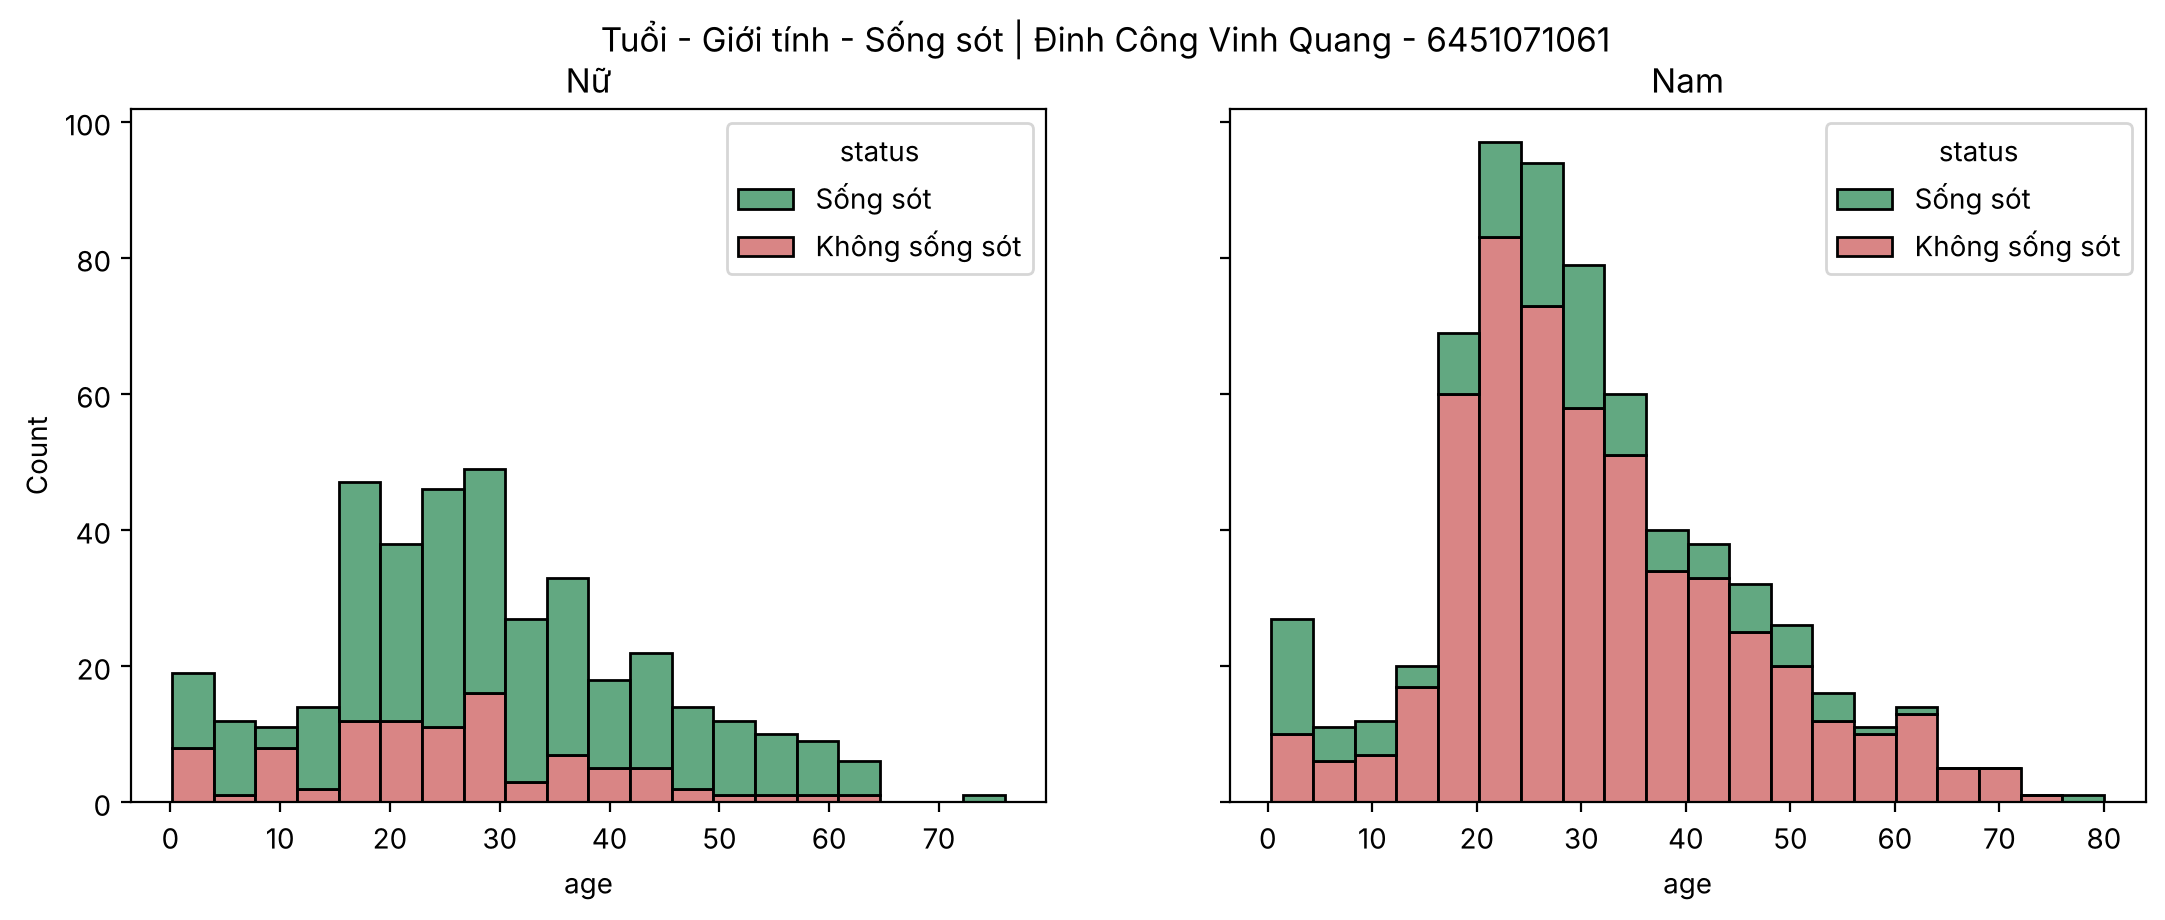

In [2]:
df = pd.read_csv("titanic.csv")
data = df.dropna(subset=["age"]).copy()
data["status"] = data["survived"].map({0: "Không sống sót", 1: "Sống sót"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, sex, name in zip(axes, ["female", "male"], ["Nữ", "Nam"]):
    sns.histplot(data=data[data["sex"] == sex], x="age", hue="status", bins=20,
                 multiple="stack", palette={"Sống sót": "seagreen", "Không sống sót": "indianred"}, ax=ax)
    ax.set_title(name)
fig.suptitle(f"Tuổi - Giới tính - Sống sót | {HO_TEN} - {MSSV}")
plt.show()

In [3]:
# tỉ lệ sống sót theo giới tính và nhóm tuổi
bands = pd.cut(data["age"], [0, 10, 18, 27, 40, 60, 100])
data.groupby(["sex", bands])["survived"].mean().unstack(0).round(3)

sex,female,male
age,,
"(0, 10]",0.610,0.556
"(10, 18]",0.745,0.125
"(18, 27]",0.733,0.194
"(27, 40]",0.770,0.188
"(40, 60]",0.831,0.187
"(60, 100]",0.857,0.077


**Nhận xét:**
- Nhìn chung nữ sống sót nhiều hơn nam rất rõ rệt (khoảng 73% so với 19%).
- Ở nam, chỉ trẻ em từ 0–10 tuổi có tỉ lệ sống sót cao (~56%); từ 11 tuổi trở lên tỉ lệ rơi xuống chỉ còn khoảng 8–19%, thấp nhất ở nhóm trên 60 tuổi (~8%); nhóm 18–40 tuổi chiếm đa số nam giới và chỉ sống sót khoảng 19%.
- Ở nữ, tỉ lệ sống sót cao ở mọi độ tuổi (61–86%) và có xu hướng tăng theo tuổi; bé gái dưới 10 tuổi thấp hơn một chút (~61%).